<a href="https://colab.research.google.com/github/elzebrejv87/adkp-metering-anomaly-detection/blob/main/Metering_Anomaly_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd

# Set seed agar hasil konsisten (reproducible)
np.random.seed(42)

# 1. Simulasi 30 hari interval 15 menit = 2.880 titik data
n_samples = 2880
timestamps = pd.date_range(start='2026-10-01 00:00:00', periods=int(n_samples), freq='15min')

# Konversi ke NumPy array (.to_numpy()) agar array arus/tegangan bisa dimodifikasi (*=)
hour = (timestamps.hour + timestamps.minute / 60.0).to_numpy()
daily_profile = 0.75 + 0.25 * np.sin((hour - 13) * np.pi / 12)

# 2. Parameter Kelistrikan Normal (Referensi GI 150 kV, Rasio CT 800/5 A, PT 150kV/100V)
V_nom = 150.0  # kV
I_base = 320.0 * daily_profile  # Ampere

V_R = np.random.normal(V_nom, 0.4, n_samples)
V_S = np.random.normal(V_nom, 0.4, n_samples)
V_T = np.random.normal(V_nom, 0.4, n_samples)

I_R = np.array(I_base + np.random.normal(0, 2.5, n_samples), dtype=float)
I_S = np.array(I_base + np.random.normal(0, 2.5, n_samples), dtype=float)
I_T = np.array(I_base + np.random.normal(0, 2.5, n_samples), dtype=float)

PF_R = np.clip(np.random.normal(0.94, 0.01, n_samples), 0.85, 0.99)
PF_S = np.clip(np.random.normal(0.94, 0.01, n_samples), 0.85, 0.99)
PF_T = np.clip(np.random.normal(0.94, 0.01, n_samples), 0.85, 0.99)

# Hitung Daya Aktif (MW) & Reaktif (MVAR) per fasa lalu konversi ke energi 15 menit (0.25 jam)
P_total_MW = ((V_R * I_R * PF_R) + (V_S * I_S * PF_S) + (V_T * I_T * PF_T)) / (np.sqrt(3) * 1000)
Q_total_MVAR = ((V_R * I_R * np.sin(np.arccos(PF_R))) +
                (V_S * I_S * np.sin(np.arccos(PF_S))) +
                (V_T * I_T * np.sin(np.arccos(PF_T)))) / (np.sqrt(3) * 1000)

# Main Meter vs Check Meter (Kelas Akurasi 0.2S -> selisih normal < 0.2%)
kWh_Export_Main = np.array(P_total_MW * 1000 * 0.25, dtype=float)
kWh_Export_Check = np.array(kWh_Export_Main * np.random.normal(1.0002, 0.0005, n_samples), dtype=float)
kVARh_Export_Main = np.array(Q_total_MVAR * 1000 * 0.25, dtype=float)

# Label ground-truth (hanya untuk evaluasi akhir, TIDAK dipakai saat melatih model unsupervised)
Ground_Truth = np.array(['Normal'] * n_samples, dtype=object)

# 3. Injeksi Skenario Anomali (Total ~4% dari data)
# Skenario A: Error Akurasi Metering / CT Drift pada Fasa S (Susut Non-Teknis)
idx_metering = np.arange(600, 645)  # Durasi ~11 jam
I_S[idx_metering] *= 0.82  # Arus fasa S terbaca turun 18% akibat burden/kabel klem longgar
kWh_Export_Main[idx_metering] *= 0.94  # Main meter mencatat lebih rendah dari Check meter
Ground_Truth[idx_metering] = 'Anomali_Metering_CT_Error'

# Skenario B: Indikasi Hot-Spot / Degradasi Koneksi (Keselamatan Proses)
idx_hotspot = np.arange(1450, 1490)  # Durasi 10 jam
I_R[idx_hotspot] *= 1.18  # Ketidakseimbangan arus meningkat
PF_R[idx_hotspot] -= 0.09  # Kenaikan daya reaktif lokal
kVARh_Export_Main[idx_hotspot] *= 1.35
Ground_Truth[idx_hotspot] = 'Anomali_Safety_HotSpot'

# Skenario C: Indikasi Awal Gangguan Isolasi / Incipient Fault (Keselamatan Proses)
idx_insulation = np.random.choice(np.arange(2000, 2700), size=35, replace=False)
I_T[idx_insulation] *= np.random.uniform(1.22, 1.35, size=35)
V_T[idx_insulation] *= 0.95
PF_T[idx_insulation] -= 0.12
kVARh_Export_Main[idx_insulation] *= 1.50
Ground_Truth[idx_insulation] = 'Anomali_Safety_Insulation'

# Susun ke DataFrame
df = pd.DataFrame({
    'Timestamp': timestamps,
    'V_R_kV': np.round(V_R, 2),
    'V_S_kV': np.round(V_S, 2),
    'V_T_kV': np.round(V_T, 2),
    'I_R_A': np.round(I_R, 2),
    'I_S_A': np.round(I_S, 2),
    'I_T_A': np.round(I_T, 2),
    'PF_R': np.round(PF_R, 3),
    'PF_S': np.round(PF_S, 3),
    'PF_T': np.round(PF_T, 3),
    'kWh_Export_Main': np.round(kWh_Export_Main, 2),
    'kWh_Export_Check': np.round(kWh_Export_Check, 2),
    'kVARh_Export_Main': np.round(kVARh_Export_Main, 2),
    'Ground_Truth': Ground_Truth
})

# Simpan ke CSV
df.to_csv('metering_transmission_data.csv', index=False)
print("Dataset berhasil dibuat! Jumlah baris:", len(df))
df.head()

Dataset berhasil dibuat! Jumlah baris: 2880


,Timestamp,V_R_kV,V_S_kV,V_T_kV,I_R_A,I_S_A,I_T_A,PF_R,PF_S,PF_T,kWh_Export_Main,kWh_Export_Check,kVARh_Export_Main,Ground_Truth
0,2026-10-01 00:00:00,150.20,149.10,150.01,264.75,264.00,260.57,0.942,0.943,0.937,16056.37,16062.16,5772.50,Normal
1,2026-10-01 00:15:00,149.94,149.15,150.21,253.68,248.34,252.36,0.946,0.932,0.944,15339.60,15352.90,5528.79,Normal
2,2026-10-01 00:30:00,150.26,149.76,149.61,253.30,247.39,252.62,0.946,0.947,0.950,15447.33,15444.62,5189.50,Normal
3,2026-10-01 00:45:00,150.61,150.18,149.44,245.69,242.94,247.09,0.926,0.943,0.930,14864.23,14884.14,5739.17,Normal
4,2026-10-01 01:00:00,149.91,148.90,150.04,240.63,237.95,238.31,0.948,0.937,0.950,14630.42,14637.42,5055.19,Normal


=== RINGKASAN DETEKSI ANOMALI ===
Rekomendasi_Tindakan
Normal                                             2759
Inspeksi Keselamatan (Thermovisi / Uji Isolasi)      76
Audit Metering (Susut / Error CT-PT)                 45
Name: count, dtype: int64

=== LAPORAN EVALUASI MODEL (1: Normal, -1: Anomali) ===
              precision    recall  f1-score   support

     Anomali       0.99      1.00      1.00       120
      Normal       1.00      1.00      1.00      2760

    accuracy                           1.00      2880
   macro avg       1.00      1.00      1.00      2880
weighted avg       1.00      1.00      1.00      2880



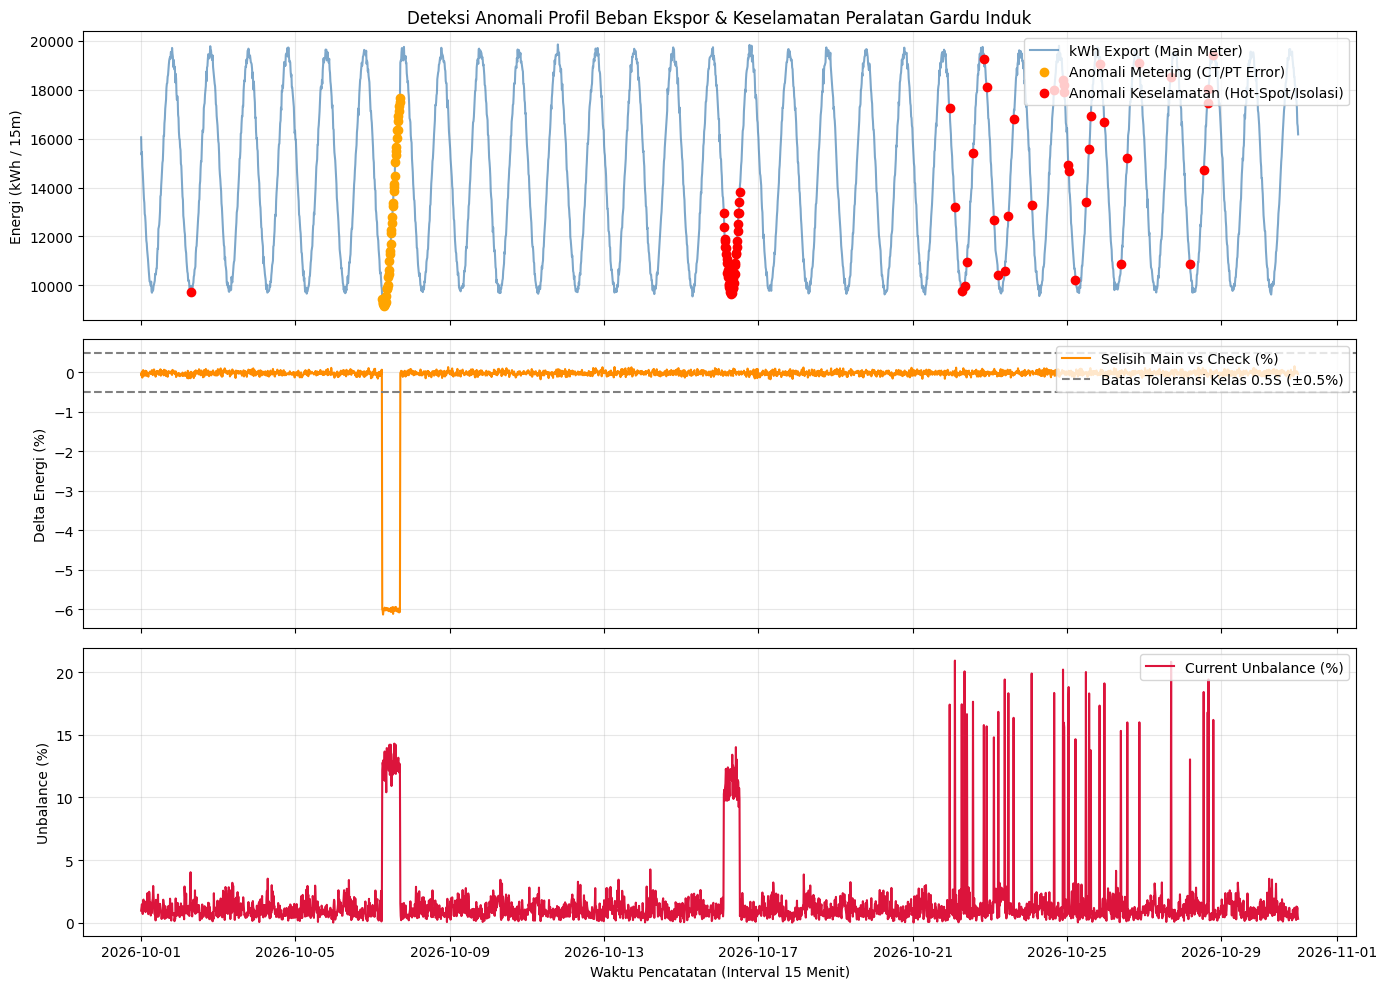

=== RINGKASAN DETEKSI ANOMALI ===
Rekomendasi_Tindakan
Normal                                             2759
Inspeksi Keselamatan (Thermovisi / Uji Isolasi)      76
Audit Metering (Susut / Error CT-PT)                 45
Name: count, dtype: int64

=== LAPORAN EVALUASI MODEL (1: Normal, -1: Anomali) ===
              precision    recall  f1-score   support

     Anomali       0.99      1.00      1.00       120
      Normal       1.00      1.00      1.00      2760

    accuracy                           1.00      2880
   macro avg       1.00      1.00      1.00      2880
weighted avg       1.00      1.00      1.00      2880



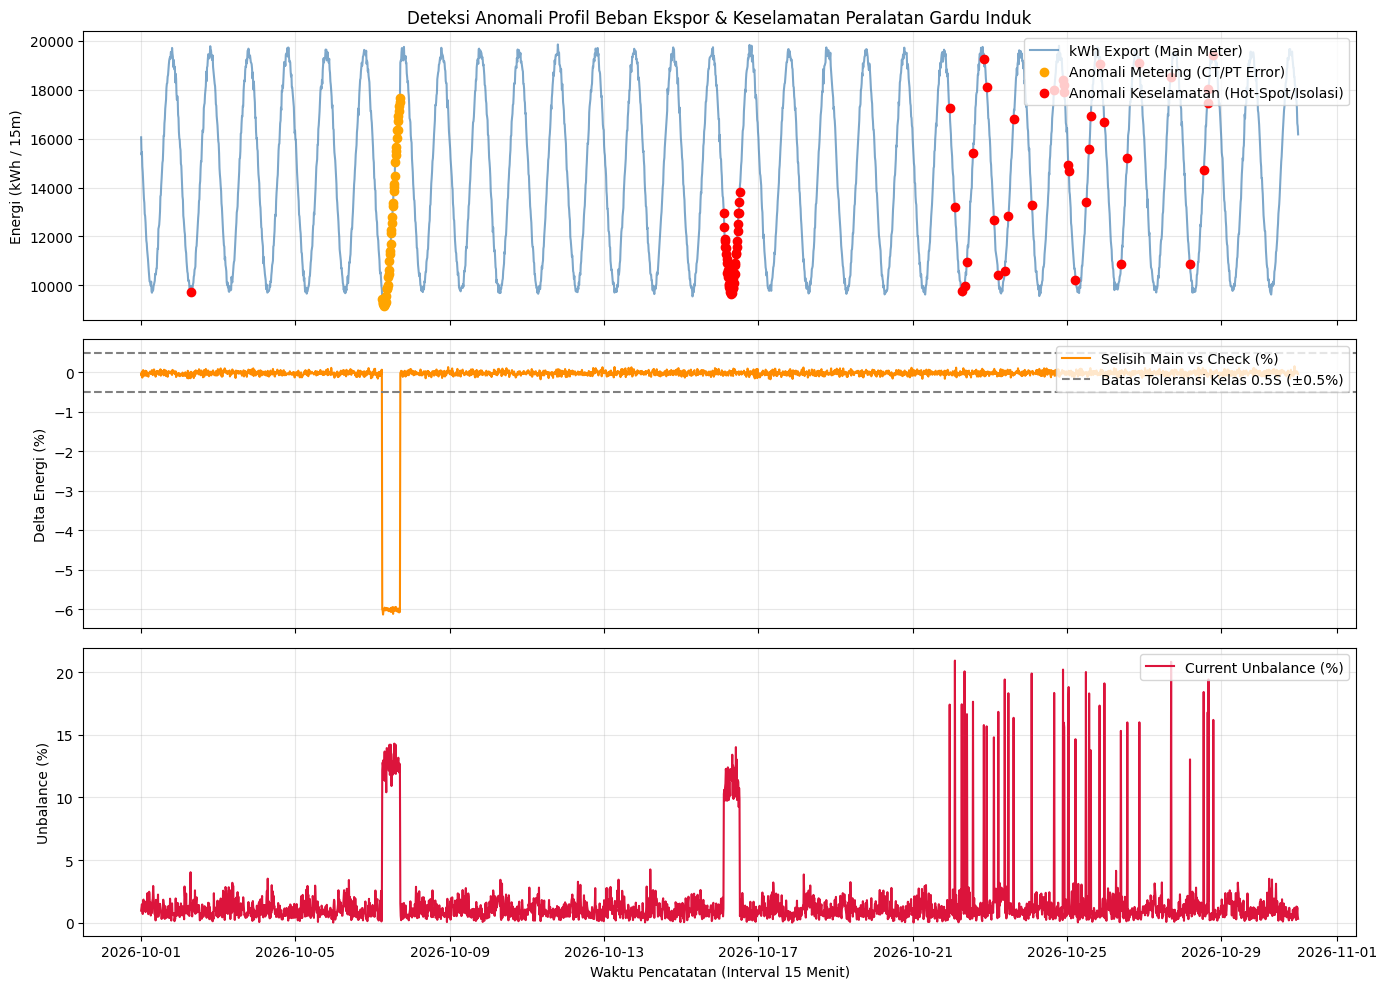

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

# 1. Load Dataset
# Gunakan baris ini dulu jika menguji langsung di Colab setelah membuat file CSV di sel 1:
df = pd.read_csv('metering_transmission_data.csv')

# Nanti setelah file CSV diunggah ke GitHub, hapus tanda '#' di bawah ini dan ganti USERNAME_ANDA:
# url_csv = "https://raw.githubusercontent.com/elzebrejv87/adkp-metering-anomaly-detection/refs/heads/main/metering_transmission_data.csv"
# df = pd.read_csv(url_csv)

df['Timestamp'] = pd.to_datetime(df['Timestamp'])

# 2. Feature Engineering (Menghitung Parameter Susut & Keselamatan Proses)
# A. Ketidakseimbangan Arus Antar Fasa (%)
I_avg = (df['I_R_A'] + df['I_S_A'] + df['I_T_A']) / 3
I_max_dev = np.maximum.reduce([
    np.abs(df['I_R_A'] - I_avg),
    np.abs(df['I_S_A'] - I_avg),
    np.abs(df['I_T_A'] - I_avg)
])
df['Current_Unbalance_Pct'] = (I_max_dev / I_avg) * 100

# B. Selisih Neraca Energi Main vs Check Meter (%) -> Indikator Susut / Error Akurasi Metering
df['Energy_Delta_Pct'] = ((df['kWh_Export_Main'] - df['kWh_Export_Check']) / df['kWh_Export_Check']) * 100

# C. Rasio Daya Reaktif terhadap Daya Aktif (tan phi) -> Indikator Beban Induktif / Degradasi Isolasi
df['Q_P_Ratio'] = df['kVARh_Export_Main'] / df['kWh_Export_Main']

# 3. Preprocessing & Pelatihan Model Unsupervised (Isolation Forest)
features = [
    'V_R_kV', 'V_S_kV', 'V_T_kV',
    'I_R_A', 'I_S_A', 'I_T_A',
    'Current_Unbalance_Pct', 'Energy_Delta_Pct', 'Q_P_Ratio'
]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

# Melatih Isolation Forest (contamination=0.04 sesuai estimasi ~4% anomali)
iso_forest = IsolationForest(n_estimators=200, contamination=0.042, random_state=42)
df['Anomaly_Pred'] = iso_forest.fit_predict(X_scaled)  # -1 = Anomali, 1 = Normal
df['Anomaly_Score'] = iso_forest.decision_function(X_scaled)

# 4. Klasifikasi Diagnostik Lapangan (Rule-Based Triage untuk Metering vs Keselamatan Proses)
def diagnosa_tindakan(row):
    if row['Anomaly_Pred'] == 1:
        return 'Normal'
    # Jika selisih Main vs Check > 0.5% (melewati kelas akurasi 0.2S/0.5S) tanpa lonjakan Q/P ekstrem
    elif abs(row['Energy_Delta_Pct']) > 0.5 and row['Q_P_Ratio'] < 0.45:
        return 'Audit Metering (Susut / Error CT-PT)'
    # Jika ketidakseimbangan arus tinggi atau rasio Q/P melonjak (indikasi hot-spot / isolasi)
    else:
        return 'Inspeksi Keselamatan (Thermovisi / Uji Isolasi)'

df['Rekomendasi_Tindakan'] = df.apply(diagnosa_tindakan, axis=1)

# 5. Evaluasi & Ringkasan Hasil
print("=== RINGKASAN DETEKSI ANOMALI ===")
print(df['Rekomendasi_Tindakan'].value_counts())

# Evaluasi biner terhadap Ground Truth
y_true_binary = np.where(df['Ground_Truth'] == 'Normal', 1, -1)
print("\n=== LAPORAN EVALUASI MODEL (1: Normal, -1: Anomali) ===")
print(classification_report(y_true_binary, df['Anomaly_Pred'], target_names=['Anomali', 'Normal']))

# 6. Visualisasi Hasil Time-Series
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# Plot 1: Profil Energi Ekspor & Titik Anomali
axes[0].plot(df['Timestamp'], df['kWh_Export_Main'], label='kWh Export (Main Meter)', color='steelblue', alpha=0.7)
anom_meter = df[df['Rekomendasi_Tindakan'] == 'Audit Metering (Susut / Error CT-PT)']
anom_safety = df[df['Rekomendasi_Tindakan'] == 'Inspeksi Keselamatan (Thermovisi / Uji Isolasi)']
axes[0].scatter(anom_meter['Timestamp'], anom_meter['kWh_Export_Main'], color='orange', label='Anomali Metering (CT/PT Error)', zorder=5)
axes[0].scatter(anom_safety['Timestamp'], anom_safety['kWh_Export_Main'], color='red', label='Anomali Keselamatan (Hot-Spot/Isolasi)', zorder=5)
axes[0].set_ylabel('Energi (kWh / 15m)')
axes[0].set_title('Deteksi Anomali Profil Beban Ekspor & Keselamatan Peralatan Gardu Induk')
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3)

# Plot 2: Selisih Neraca Energi Main vs Check Meter (%)
axes[1].plot(df['Timestamp'], df['Energy_Delta_Pct'], color='darkorange', label='Selisih Main vs Check (%)')
axes[1].axhline(0.5, color='gray', linestyle='--', label='Batas Toleransi Kelas 0.5S (±0.5%)')
axes[1].axhline(-0.5, color='gray', linestyle='--')
axes[1].set_ylabel('Delta Energi (%)')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

# Plot 3: Ketidakseimbangan Arus Antar Fasa (%)
axes[2].plot(df['Timestamp'], df['Current_Unbalance_Pct'], color='crimson', label='Current Unbalance (%)')
axes[2].set_ylabel('Unbalance (%)')
axes[2].set_xlabel('Waktu Pencatatan (Interval 15 Menit)')
axes[2].legend(loc='upper right')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Jika ingin tes lokal di Colab sebelum upload URL, gunakan: df = pd.read_csv('metering_transmission_data.csv')
df = pd.read_csv('metering_transmission_data.csv')
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

# 2. Feature Engineering (Menghitung Parameter Susut & Keselamatan Proses)
# A. Ketidakseimbangan Arus Antar Fasa (%)
I_avg = (df['I_R_A'] + df['I_S_A'] + df['I_T_A']) / 3
I_max_dev = np.maximum.reduce([
    np.abs(df['I_R_A'] - I_avg),
    np.abs(df['I_S_A'] - I_avg),
    np.abs(df['I_T_A'] - I_avg)
])
df['Current_Unbalance_Pct'] = (I_max_dev / I_avg) * 100

# B. Selisih Neraca Energi Main vs Check Meter (%) -> Indikator Susut / Error Akurasi Metering
df['Energy_Delta_Pct'] = ((df['kWh_Export_Main'] - df['kWh_Export_Check']) / df['kWh_Export_Check']) * 100

# C. Rasio Daya Reaktif terhadap Daya Aktif (tan phi) -> Indikator Beban Induktif / Degradasi Isolasi
df['Q_P_Ratio'] = df['kVARh_Export_Main'] / df['kWh_Export_Main']

# 3. Preprocessing & Pelatihan Model Unsupervised (Isolation Forest)
features = [
    'V_R_kV', 'V_S_kV', 'V_T_kV',
    'I_R_A', 'I_S_A', 'I_T_A',
    'Current_Unbalance_Pct', 'Energy_Delta_Pct', 'Q_P_Ratio'
]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

# Melatih Isolation Forest (contamination=0.04 sesuai estimasi ~4% anomali)
iso_forest = IsolationForest(n_estimators=200, contamination=0.042, random_state=42)
df['Anomaly_Pred'] = iso_forest.fit_predict(X_scaled)  # -1 = Anomali, 1 = Normal
df['Anomaly_Score'] = iso_forest.decision_function(X_scaled)

# 4. Klasifikasi Diagnostik Lapangan (Rule-Based Triage untuk Metering vs Keselamatan Proses)
def diagnosa_tindakan(row):
    if row['Anomaly_Pred'] == 1:
        return 'Normal'
    # Jika selisih Main vs Check > 0.5% (melewati kelas akurasi 0.2S/0.5S) tanpa lonjakan Q/P ekstrem
    elif abs(row['Energy_Delta_Pct']) > 0.5 and row['Q_P_Ratio'] < 0.45:
        return 'Audit Metering (Susut / Error CT-PT)'
    # Jika ketidakseimbangan arus tinggi atau rasio Q/P melonjak (indikasi hot-spot / isolasi)
    else:
        return 'Inspeksi Keselamatan (Thermovisi / Uji Isolasi)'

df['Rekomendasi_Tindakan'] = df.apply(diagnosa_tindakan, axis=1)

# 5. Evaluasi & Ringkasan Hasil
print("=== RINGKASAN DETEKSI ANOMALI ===")
print(df['Rekomendasi_Tindakan'].value_counts())

# Evaluasi biner terhadap Ground Truth
y_true_binary = np.where(df['Ground_Truth'] == 'Normal', 1, -1)
print("\n=== LAPORAN EVALUASI MODEL (1: Normal, -1: Anomali) ===")
print(classification_report(y_true_binary, df['Anomaly_Pred'], target_names=['Anomali', 'Normal']))

# 6. Visualisasi Hasil Time-Series
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# Plot 1: Profil Energi Ekspor & Titik Anomali
axes[0].plot(df['Timestamp'], df['kWh_Export_Main'], label='kWh Export (Main Meter)', color='steelblue', alpha=0.7)
anom_meter = df[df['Rekomendasi_Tindakan'] == 'Audit Metering (Susut / Error CT-PT)']
anom_safety = df[df['Rekomendasi_Tindakan'] == 'Inspeksi Keselamatan (Thermovisi / Uji Isolasi)']
axes[0].scatter(anom_meter['Timestamp'], anom_meter['kWh_Export_Main'], color='orange', label='Anomali Metering (CT/PT Error)', zorder=5)
axes[0].scatter(anom_safety['Timestamp'], anom_safety['kWh_Export_Main'], color='red', label='Anomali Keselamatan (Hot-Spot/Isolasi)', zorder=5)
axes[0].set_ylabel('Energi (kWh / 15m)')
axes[0].set_title('Deteksi Anomali Profil Beban Ekspor & Keselamatan Peralatan Gardu Induk')
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3)

# Plot 2: Selisih Neraca Energi Main vs Check Meter (%)
axes[1].plot(df['Timestamp'], df['Energy_Delta_Pct'], color='darkorange', label='Selisih Main vs Check (%)')
axes[1].axhline(0.5, color='gray', linestyle='--', label='Batas Toleransi Kelas 0.5S (±0.5%)')
axes[1].axhline(-0.5, color='gray', linestyle='--')
axes[1].set_ylabel('Delta Energi (%)')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

# Plot 3: Ketidakseimbangan Arus Antar Fasa (%)
axes[2].plot(df['Timestamp'], df['Current_Unbalance_Pct'], color='crimson', label='Current Unbalance (%)')
axes[2].set_ylabel('Unbalance (%)')
axes[2].set_xlabel('Waktu Pencatatan (Interval 15 Menit)')
axes[2].legend(loc='upper right')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()